# Session 3: Normal Approximation of the Binomial

*ECE 225A, Module 04 (The Normal Distribution), deck 9.Normal_approximation_binomial_distribution, slides 1-17*

The binomial distribution is everywhere, but its probabilities are awkward: huge factorials for a single value, and long sums for an interval. The De Moivre-Laplace theorem says that near its mean, the binomial PMF is close to the normal density with the same mean and variance. That replaces one hard formula with an easy one, but three questions remain. A continuous variable gives any single value probability 0, so in what sense does a binomial probability equal a normal one? Must interval probabilities still be summed term by term? And can the Z table help? All three have one answer: the **continuity correction**, which reads a density at $k$ as the probability of the interval from $k - \frac{1}{2}$ to $k + \frac{1}{2}$.

## Learning objectives

After this session you should be able to:

1. State the De Moivre-Laplace theorem, including what $\simeq$ means and for which $k$ it holds.
2. Approximate $B_{p,n}(k)$ by $N_{np,npq}(k)$, and judge when the approximation is good.
3. Prove the theorem for $k = np$ with Stirling's approximation.
4. Explain why $P(X = k) \approx P(Y = k)$ is false, and why a density at $k$ nearly equals a probability over a unit interval.
5. Apply the continuity correction to single values and intervals, and use the Z table to find them.
6. Translate any event about a binomial, with strict or non-strict inequalities, into the correct normal event.

## Prerequisites

- The binomial distribution, with $\mu = np$, $V = npq$ (Module 01, Session 5).
- Stirling's approximation and the central binomial term (Module 02, Session 1).
- The normal density (Session 1).
- Z scores, $\Phi$, and the Z table (Session 2).

In [1]:
from math import comb, exp, factorial, pi, sqrt

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom, norm

rng = np.random.default_rng(225)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, FAINT, GRID = "#0b0b0b", "#52514e", "#c3c2b7", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})

Phi = norm.cdf


def normal_density(x, mu, var):
    # The density N_{mu, var}(x), written out from the definition.
    return np.exp(-(x - mu) ** 2 / (2 * var)) / np.sqrt(2 * pi * var)


def normal_interval(a, b, mu, var):
    # P(a <= Y <= b) for Y ~ N_{mu, var}, by standardizing.
    sigma = sqrt(var)
    return Phi((b - mu) / sigma) - Phi((a - mu) / sigma)

## 1. Why approximate? (slides 1-2)

The binomial is significant but complicated. It can be approximated by a normal distribution, but which one? The natural choice is the normal with the **same mean and variance**:

$$B_{p,n} \text{ has } \mu = np \text{ and } V = npq, \quad \text{so use } N_{np,\,npq}.$$

Then, for all $k \approx np$,

$$B_{p,n}(k) \approx N_{np,npq}(k),$$

where the left side is a binomial probability, and the right side is the normal *density* evaluated at $k$.

**Example.** For $B_{1/4,\,48}$, we have $\mu = 48 \cdot \frac{1}{4} = 12$ and $V = 12 \cdot \frac{3}{4} = 9$, so use $N_{12,9}$.

(The slides write the subscripts in both orders, $B_{n,p}$ and $B_{p,n}$. We follow Module 01 and write $B_{p,n}$. So the $B_{48,1/4}$ on slide 2 is our $B_{1/4,\,48}$.)

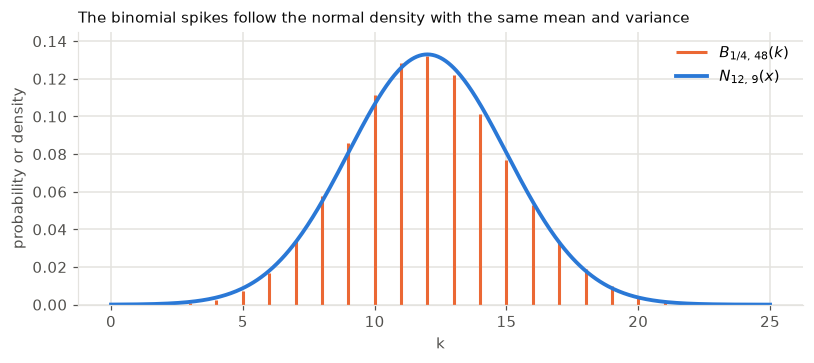

In [2]:
n, p = 48, 1 / 4
mu, var = n * p, n * p * (1 - p)
ks = np.arange(0, 26)
xs = np.linspace(0, 25, 501)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.vlines(ks, 0, binom.pmf(ks, n, p), color=ORANGE, lw=2, label=r"$B_{1/4,\,48}(k)$")
ax.plot(xs, normal_density(xs, mu, var), color=BLUE, lw=2.5, label=r"$N_{12,\,9}(x)$")
ax.set(xlabel="k", ylabel="probability or density", ylim=(0, 0.145))
ax.legend(frameon=False)
ax.set_title("The binomial spikes follow the normal density with the same mean and variance", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 2. The De Moivre-Laplace theorem (slide 3)

**Theorem.** Let $B_{p,n}$ have $\mu = np$, $V = npq$, and $\sigma = \sqrt{npq}$, with $q = 1 - p$. For every $p \in (0, 1)$ and every $c > 0$, as $n \to \infty$, for all $k$ with

$$\lvert k - np \rvert \le c\sqrt{npq},$$

that is, for $k$ within $c$ standard deviations of $\mu$,

$$B_{p,n}(k) \simeq N_{np,npq}(k).$$

Here $\simeq$ means that the ratio of the left and right sides tends to 1.

The next sections give an example, and prove the case $k = np$. A later generalization to sums of other independent variables is the Central Limit Theorem.

In [3]:
# Worst ratio B/N over all k within c standard deviations of the mean, as n grows.
p, q = 1 / 4, 3 / 4
print("    n     c = 1              c = 2              c = 3")
for n in [48, 480, 4_800, 48_000, 480_000]:
    mu, var = n * p, n * p * q
    cells = []
    for c in (1, 2, 3):
        lo, hi = int(np.ceil(mu - c * sqrt(var))), int(np.floor(mu + c * sqrt(var)))
        k = np.arange(lo, hi + 1)
        ratio = binom.pmf(k, n, p) / normal_density(k, mu, var)
        cells.append(f"[{ratio.min():.4f}, {ratio.max():.4f}]")
    print(f"{n:7,}  " + "   ".join(cells))

    n     c = 1              c = 2              c = 3
     48  [0.9511, 1.0636]   [0.9417, 1.0636]   [0.4366, 1.4538]
    480  [0.9831, 1.0182]   [0.9831, 1.0183]   [0.8462, 1.1430]
  4,800  [0.9945, 1.0056]   [0.9944, 1.0056]   [0.9494, 1.0495]
 48,000  [0.9983, 1.0018]   [0.9983, 1.0018]   [0.9843, 1.0156]
480,000  [0.9994, 1.0006]   [0.9994, 1.0006]   [0.9950, 1.0050]


## 3. The approximation in action, take 1 (slide 4)

**Problem.** Find $B_{0.5,\,100}(60)$.

**Exact.**

$$B_{0.5,\,100}(60) = \binom{100}{60}\, 0.5^{60} \cdot (1 - 0.5)^{40} \approx 0.010844.$$

**Normal approximation.** Use the same mean and variance, $\mu = 100 \cdot 0.5 = 50$ and $\sigma^2 = 100 \cdot 0.5 \cdot 0.5 = 25$. The exponent is $-\frac{(60 - 50)^2}{2 \cdot 25} = -2$, so

$$B_{0.5,\,100}(60) \simeq N_{50,25}(60) = \frac{1}{\sqrt{2\pi \cdot 25}}\, e^{-2} \approx 0.010798,$$

which is only 0.4% below the exact value. The approximation improves as $npq \to \infty$ and as $k \to np$.

In [4]:
exact = comb(100, 60) * 0.5 ** 100
approx = normal_density(60, 50, 25)
print(f"exact  {exact:.6f}")
print(f"normal {approx:.6f}")
print(f"relative error {(approx - exact) / exact:+.2%}\n")

print("The approximation improves as npq grows, and as k approaches np:")
print("     n    p    k    exact        normal       relative error")
for n, p, k in [(20, 0.5, 14), (100, 0.5, 60), (100, 0.5, 70), (1_000, 0.5, 530), (1_000, 0.5, 500), (100, 0.1, 18), (10_000, 0.1, 1_040)]:
    mu, var = n * p, n * p * (1 - p)
    b, m = binom.pmf(k, n, p), normal_density(k, mu, var)
    print(f"{n:6} {p:4} {k:5}  {b:.4e}   {m:.4e}   {(m - b) / b:+.2%}")

exact  0.010844
normal 0.010798
relative error -0.42%

The approximation improves as npq grows, and as k approaches np:
     n    p    k    exact        normal       relative error
    20  0.5    14  3.6964e-02   3.6021e-02   -2.55%
   100  0.5    60  1.0844e-02   1.0798e-02   -0.42%
   100  0.5    70  2.3171e-05   2.6766e-05   +15.52%
  1000  0.5   530  4.1727e-03   4.1707e-03   -0.05%
  1000  0.5   500  2.5225e-02   2.5231e-02   +0.03%
   100  0.1    18  5.4265e-03   3.7987e-03   -30.00%
 10000  0.1  1040  5.4281e-03   5.4670e-03   +0.72%


## 4. Proof for $k = np$ (slide 5)

**Claim.** For all $p$, as $n \to \infty$, $B_{p,n}(k) \simeq N_{pn,pqn}(k)$ at $k = pn$. (Assume that $pn$ is an integer.)

**The binomial side.** With $q = 1 - p$,

$$B_{p,n}(pn) = \binom{n}{pn} p^{pn} q^{qn} = \frac{n!}{(pn)!\, (qn)!}\, p^{pn} q^{qn}.$$

Apply **Stirling's approximation**, $n! \simeq \sqrt{2\pi n}\, (n/e)^n$, to all three factorials, which is valid as $n \to \infty$:

$$\simeq \frac{\sqrt{2\pi n}\, (n/e)^n}{\sqrt{2\pi pn}\, (pn/e)^{pn} \cdot \sqrt{2\pi qn}\, (qn/e)^{qn}} \cdot p^{pn} q^{qn}.$$

Now cancel, using $pn + qn = n$:

- Powers of $n/e$: $(n/e)^n$ on top cancels $(n/e)^{pn}(n/e)^{qn}$ on the bottom.
- Powers of $p$ and $q$: $p^{pn} q^{qn}$ on the bottom cancels the same factor on the right.
- Square roots: $\frac{\sqrt{2\pi n}}{\sqrt{2\pi pn}\, \sqrt{2\pi qn}} = \frac{1}{\sqrt{2\pi \cdot pqn}}$.

So $B_{p,n}(pn) \simeq \frac{1}{\sqrt{2\pi \cdot pqn}}$.

**The normal side.** At its own mean the exponent vanishes:

$$N_{pn,pqn}(pn) = \frac{1}{\sqrt{2\pi \cdot pqn}}\, e^{-\frac{(pn - pn)^2}{2 \cdot pqn}} = \frac{1}{\sqrt{2\pi \cdot pqn}}.$$

The two sides agree. $\checkmark$

**A link to Module 02.** With $p = \frac{1}{2}$ and $2n$ trials, this says $\frac{1}{\sqrt{2\pi \cdot \frac{1}{4} \cdot 2n}} = \frac{1}{\sqrt{\pi n}}$, the central binomial rate from the "Why Vote" session. The peak is about $0.4/\sigma$, which is the "peak is about $1/\sigma$" rule made exact.

In [5]:
print("    n    p    B(np)          1/sqrt(2 pi npq)    ratio")
for n, p in [(10, 0.5), (100, 0.5), (10_000, 0.5), (100, 0.2), (10_000, 0.2), (100, 0.7), (10_000, 0.7)]:
    k = round(n * p)
    b = binom.pmf(k, n, p)
    m = 1 / sqrt(2 * pi * n * p * (1 - p))
    print(f"{n:6} {p:4}   {b:.6f}       {m:.6f}          {b / m:.6f}")

print("\nStirling for 20!:")
print(f"  exact {factorial(20):.5e}, Stirling {sqrt(2 * pi * 20) * (20 / np.e) ** 20:.5e}")

    n    p    B(np)          1/sqrt(2 pi npq)    ratio
    10  0.5   0.246094       0.252313          0.975350
   100  0.5   0.079589       0.079788          0.997503
 10000  0.5   0.007979       0.007979          0.999975
   100  0.2   0.099300       0.099736          0.995635
 10000  0.2   0.009973       0.009974          0.999956
   100  0.7   0.086784       0.087056          0.996870
 10000  0.7   0.008705       0.008706          0.999969

Stirling for 20!:
  exact 2.43290e+18, Stirling 2.42279e+18


## 5. Three questions (slides 6-9)

The approximation is useful, but it leaves three questions open.

**Quiz 1.** Suppose $X \sim B_{p,n}$ and $Y \sim N_{pn,pqn}$, with $p$, $n$, $k$ as above. Then is $P(X = k) \approx P(Y = k)$? **No!**

$$P(X = k) = \binom{n}{k} p^k q^{n-k} \approx \frac{1}{\sqrt{2\pi \cdot npq}}\, e^{-\frac{(k - \mu)^2}{2npq}} > 0, \qquad \text{but} \qquad P(Y = k) = 0,$$

since $Y$ is continuous. A binomial **probability** approximates a normal **density**, not a normal probability. Can a probability be made to appear instead?

**Quiz 2.** We approximated a binomial probability of one value, $P(X = k)$. What about an interval, $P(k_1 \le X \le k_2)$? We can sum, $\sum_{k = k_1}^{k_2} P(X = k)$, and approximate each term. Can we do better?

**Quiz 3.** We worked hard to derive and understand the Z table. Can we use it here?

The next topic answers all three.